In [9]:
!pip install -q tensorflow pandas scikit-learn google-api-python-client

In [10]:
!pip install kaggle

from google.colab import files
files.upload()  # kaggle.json dosyanı yükle

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


Saving magaza_yorumlari_duygu_analizi.csv to magaza_yorumlari_duygu_analizi (2).csv
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [20]:
import pandas as pd

df = pd.read_csv("/content/magaza_yorumlari_duygu_analizi.csv", encoding="utf-16")

print(df.head())
print(df.columns)

# Tarafsızları çıkar
df = df[df['Durum'] != 'Tarafsız']

# Etiketleri numeric label'a çevir
df['label'] = df['Durum'].apply(lambda x: 1 if x == 'Olumlu' else 0)

print(df['label'].value_counts())
print(df.head())


                                               Görüş     Durum
0  ses kalitesi ve ergonomisi rezalet, sony olduğ...   Olumsuz
1                         hizli teslimat tesekkürler  Tarafsız
2  ses olayı süper....gece çalıştır sıkıntı yok.....    Olumlu
3  geldi bigün kullandık hemen bozoldu hiçtavsiye...   Olumsuz
4  Kulaklığın sesi kaliteli falan değil. Aleti öv...   Olumsuz
Index(['Görüş', 'Durum'], dtype='object')
label
1    4253
0    4238
Name: count, dtype: int64
                                               Görüş    Durum  label
0  ses kalitesi ve ergonomisi rezalet, sony olduğ...  Olumsuz      0
2  ses olayı süper....gece çalıştır sıkıntı yok.....   Olumlu      1
3  geldi bigün kullandık hemen bozoldu hiçtavsiye...  Olumsuz      0
4  Kulaklığın sesi kaliteli falan değil. Aleti öv...  Olumsuz      0
6                                    kullanisli baya   Olumlu      1


In [21]:
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('turkish'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = ' '.join([word for word in text.split() if word not in stop_words])
    return text

df['clean_text'] = df['Görüş'].apply(clean_text)
print(df[['Görüş', 'clean_text']].head())


                                               Görüş  \
0  ses kalitesi ve ergonomisi rezalet, sony olduğ...   
2  ses olayı süper....gece çalıştır sıkıntı yok.....   
3  geldi bigün kullandık hemen bozoldu hiçtavsiye...   
4  Kulaklığın sesi kaliteli falan değil. Aleti öv...   
6                                    kullanisli baya   

                                          clean_text  
0  ses kalitesi ergonomisi rezalet sony olduğu al...  
2  ses olayı süpergece çalıştır sıkıntı yokkablo ...  
3  geldi bigün kullandık hemen bozoldu hiçtavsiye...  
4  kulaklığın sesi kaliteli falan değil aleti öve...  
6                                    kullanisli baya  


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [22]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])
sequences = tokenizer.texts_to_sequences(df['clean_text'])
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post')


In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential()
model.add(Embedding(input_dim=max_words, output_dim=128, input_length=max_len))
model.add(LSTM(64, return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(32))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

labels = df['label'].values

history = model.fit(
    padded_sequences,
    labels,
    epochs=50,
    batch_size=64,
    validation_split=0.2
)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.4988 - loss: 0.6953 - val_accuracy: 0.4944 - val_loss: 0.6933
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4991 - loss: 0.6932 - val_accuracy: 0.5044 - val_loss: 0.6930
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5065 - loss: 0.6924 - val_accuracy: 0.5044 - val_loss: 0.6945
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5028 - loss: 0.6902 - val_accuracy: 0.6904 - val_loss: 0.6116
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6996 - loss: 0.6085 - val_accuracy: 0.6986 - val_loss: 0.6080
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7062 - loss: 0.6022 - val_accuracy: 0.7098 - val_loss: 0.6038
Epoch 7/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7038 - loss: 0.6077 - val_accuracy: 0.7104 - val_loss: 0.6028
Epoch 8/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6684 - loss: 0.6281 - val_accu

In [26]:
from googleapiclient.discovery import build

api_key = 'REDACTED_GOOGLE_API_KEY'
video_id = 'yP2weCj6yaM'

youtube = build('youtube', 'v3', developerKey=api_key)

comments = []
next_page_token = None

while True:
    response = youtube.commentThreads().list(
        part='snippet',
        videoId=video_id,
        maxResults=100,
        pageToken=next_page_token,
        textFormat="plainText"
    ).execute()

    for item in response['items']:
        comment = item['snippet']['topLevelComment']['snippet']['textDisplay']
        comments.append(comment)

    if 'nextPageToken' in response:
        next_page_token = response['nextPageToken']
    else:
        break

print(f"{len(comments)} yorum çekildi.")


906 yorum çekildi.


In [27]:
comments_cleaned = [clean_text(comment) for comment in comments]
comment_sequences = tokenizer.texts_to_sequences(comments_cleaned)
comment_padded = pad_sequences(comment_sequences, maxlen=max_len, padding='post')

predictions = model.predict(comment_padded)
results = ['Pozitif' if p > 0.5 else 'Negatif' for p in predictions]

for comment, result in zip(comments, results):
    print(f"{comment[:50]}... --> {result}")


29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Hocam bu millet galiba maçı izlemeyin özet ile Ard... --> Negatif
Juventus da güzel oynamış... --> Pozitif
Arda'nın sıradan bir topçu olduğu açık.... --> Negatif
Helal olsun bizim çocuklar takımlarını 10ar kişi o... --> Pozitif
O değilde sergenin denizliye attığı frikik golü ne... --> Negatif
Kenan bence vini gibi oynadi hatta indan da iyiydi... --> Pozitif
Bal Verde güzel şutlar vurdu... --> Pozitif
Kenanin bası kel mi niye kapağa onu da koymuyorsun... --> Negatif
Kenan realde olsa net her maç gölü asisti olur.... --> Negatif
Kolo muani kazması Kenan'ın asistini yemiş. O pozi... --> Pozitif
Kaleci neler yapiyorsun... --> Negatif
congrat arda güler... --> Pozitif
Real'de bi Valverde gerçeği var. Adam her şartta ş... --> Negatif
kayınbabam üstün bir gameplay olduğunu söyledi... --> Pozitif
Xavi Alonso :kaleyi gördüğünüzde vurun... --> Negatif
Kenan kaç kurtul olm şu loser takımdan. Juventus k... --> Negatif
Herkes arda Kenan demiş ama o kaleci ney

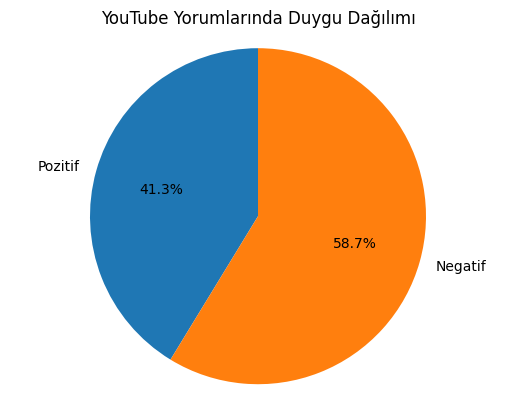

In [28]:
import matplotlib.pyplot as plt

labels_graph = ['Pozitif', 'Negatif']
sizes = [results.count('Pozitif'), results.count('Negatif')]

plt.pie(sizes, labels=labels_graph, autopct='%1.1f%%', startangle=90)
plt.axis('equal')
plt.title("YouTube Yorumlarında Duygu Dağılımı")
plt.show()
